Entrenamiento: (120, 4) | Prueba: (30, 4)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

Exactitud final en entrenamiento: 0.852
Exactitud en prueba: 0.767
Probabilidades: [0.975 0.011 0.014]
Especie predicha: setosa
Modelo guardado en modelo_iris_epochs20.keras


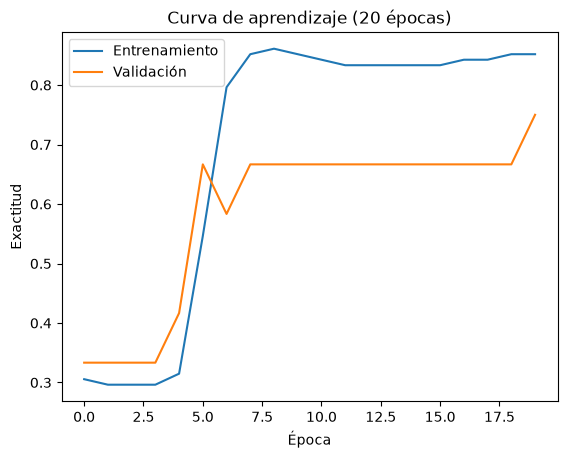

In [1]:
# 05_red_iris.py - Red neuronal multicapa con epochs=20
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(42)

# 1. Datos: 150 flores, 4 medidas, 3 especies
iris = load_iris()
X, y = iris.data, iris.target
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

escalador = StandardScaler()                 
X_ent = escalador.fit_transform(X_ent)
X_pru = escalador.transform(X_pru)
print("Entrenamiento:", X_ent.shape, "| Prueba:", X_pru.shape)

# 2. Arquitectura: 4 entradas -> 10 (ReLU) -> 8 (ReLU) -> 3 (Softmax)
modelo = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Dense(10, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(3, activation="softmax"),   
])
modelo.summary()

# 3. Compilar: optimizador, función de pérdida y métrica
modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# 4. Entrenar con epochs=20
historial = modelo.fit(X_ent, y_ent, epochs=20, batch_size=8, validation_split=0.1, verbose=0)
print("Exactitud final en entrenamiento:", round(historial.history["accuracy"][-1], 3))

# 5. Evaluar con datos que la red nunca vio
perdida, exactitud = modelo.evaluate(X_pru, y_pru, verbose=0)
print(f"Exactitud en prueba: {exactitud:.3f}")

# 6. Predecir una flor nueva
flor = escalador.transform([[5.1, 3.5, 1.4, 0.2]])
prob = modelo.predict(flor, verbose=0)[0]
print("Probabilidades:", prob.round(3))
print("Especie predicha:", iris.target_names[np.argmax(prob)])

# 7. Guardar el modelo entrenado y la curva de aprendizaje (20 épocas)
modelo.save("modelo_iris_epochs20.keras")
print("Modelo guardado en modelo_iris_epochs20.keras")

plt.plot(historial.history["accuracy"], label="Entrenamiento")
plt.plot(historial.history["val_accuracy"], label="Validación")
plt.title("Curva de aprendizaje (20 épocas)")
plt.xlabel("Época")
plt.ylabel("Exactitud")
plt.legend()
plt.savefig("curva_aprendizaje_epochs20.png", dpi=100, bbox_inches="tight")
plt.show()